# DATASCI 350 - Data Science Computing

## Assignment 09 - Parallel computing and SQL

### Instructions

This assignment evaluates your understanding of lectures 21 and 22: serial and parallel execution, `joblib`, Amdahl's law, Dask, storage formats, and SQL with DuckDB.

Some tasks are reading and reasoning about material you already have. Most ask you to run code and explain what came back.

Seven tasks ask you to run code: tasks 03, 04, 06, 07, 08, 09 and 10. Install what they need with `pip install joblib numpy duckdb pandas dask`. Tasks 03 and 04 use the `%timeit` magic, so run them inside Jupyter or IPython rather than in a plain `python` script.

Tasks 06 to 10 use one file, `wdi_panel.parquet`, which is 450 KB. Download it once with the `curl` line in task 06 and reuse it for the other four. Nothing else in this assignment downloads anything.

Your timings will not match mine, and they do not need to. Core counts, memory and background processes differ between machines. Report what your machine did, paste the actual output, and answer the questions about the numbers you got. Do not edit outputs.

You must complete this assignment individually. You may use notes, books, and AI tools, but you must submit original work. I strongly recommend that you do not use AI tools to generate your solutions, as this will not help you learn the material. Acknowledge all resources used, including input from classmates and AI, in a short note at the end of your submission. If you are unsure about permissible resources or proper acknowledgement, please ask the instructor.

### Submission

Please submit your solutions as either a single Jupyter notebook or a PDF file. For each task, paste the commands you ran, any code you wrote, the output you got, and your written answer where the task asks for one. Screenshots are welcome but not required if you paste the text. Submit your completed assignment to Canvas.

### Task 01

Here are three jobs.

1. Resizing 400 holiday photographs to thumbnails. Each photograph is a separate file and none of them depends on another.
2. Computing a running total over a column of 400 numbers, where each entry is the previous total plus the next number.
3. Fetching 200 web pages and saving the HTML of each one.

For each job, say which fits best: embarrassingly parallel, the kind of job threads help with, or neither. A job can fit more than one; if so, say which and why. One line per job is enough.

Then answer in a few sentences: pick the job that does not benefit from either approach and say what about it blocks parallel work.

Hint: the "Serial vs parallel execution" slide of lecture 21 defines embarrassingly parallel, and the `concurrent.futures` slide separates CPU-bound from I/O-bound work.

**1. This is embarrassingly parallel because each resizing task is independent and doesn't rely on results from others.<br><br>
2. Neither helps with this job.<br><br> 
3. This job is embarrassingly parallel because each fetch is independent and doesn't rely on results from others. It is also the kind of job that threads help with because it's a series of downloads so the threads can keep working while one waits.**<br><br>

**The second job does not benefit from either approach. Because each task relies on the result from another, since it's computing a running total, this blocks parallel work.**

### Task 02

Amdahl's law says the speed-up you can get from `N` cores is

```text
speedup = 1 / (s + p / N)
```

where `s` is the share of the program that must run serially and `p = 1 - s` is the share that can be split across cores.

You have profiled a program and found that a quarter of its runtime is serial: `s = 0.25`, so `p = 0.75`.

Compute the speed-up for each of these, showing the arithmetic, not just the final number, and round each speed-up to two decimal places:

- 4 cores
- 8 cores
- 32 cores
- infinitely many cores

Then answer in a few sentences: which of the two jumps buys you the least extra speed per added core, 4 to 8 cores or 8 to 32 cores? Show the division. Given the ceiling you computed for infinitely many cores, say what you would work on instead of buying more cores.

Hint: the "Amdahl's law: the speed-up ceiling" slide of lecture 21 works through the same arithmetic with `s = 0.1` on 8 cores.

**- 4 cores: speedup = 1/(0.25+0.75/4) = 2.29**<br>
**- 8 cores: speedup = 1/(0.25+0.75/8) = 2.91**<br>
**- 32 cores: speedup = 1/(0.25+0.75/32) = 3.66**<br>
**- infinitely many cores: speedup = 1/(0.25+0.75/N) and as N approaches infinity, 0.75/N approaches 0, so speedup = 1/0.25 = 4**

**4-8 cores: (2.91-2.29)/(8-4) = 0.155**<br>
**8-32 cores: (3.66-2.91)/(32-8) = 0.03125**

**As shown above, the 8 to 32 cores jump buys the least extra speed per added core.**

**Instead of buying more cores, I would work on decreasing the share of the program that must run serially (or increasing the share of the program that can be run in parallel).**

### Task 03

This task times the same work three ways on your own machine. Run it in Jupyter or IPython, because `%timeit` is a notebook magic and does not work in a plain script.

Start by reporting your core count:

```python
import os
print(os.cpu_count())
```

Then define the function from the "Serial vs parallel execution" slide of lecture 21:

```python
import numpy as np
from joblib import Parallel, delayed

def calculation(size=10000000):
    # Create a large array and perform operations
    arr = np.random.rand(size)
    for _ in range(10):
        arr = np.sqrt(arr) + np.sin(arr)
    return np.mean(arr)
```

Now time three things, one cell each, and paste all three results:

```python
%timeit calculation()
```

```python
%timeit [calculation() for _ in range(4)]
```

```python
%timeit Parallel(n_jobs=4)(delayed(calculation)() for _ in range(4))
```

Then answer two things.

1. Divide your serial time for four calls by your parallel time for four calls, and report that number as your speed-up. Show the division.
2. In a few sentences, say why the speed-up is less than 4 even though you asked for four workers, and name two things joblib has to do that the serial version does not.

Your numbers will differ from mine and from your classmates'. That is expected, and you are graded on the reasoning, not the milliseconds.

Hint: the "Serial vs parallel execution" slide of lecture 21 runs exactly these three timings and the last bullet on the right names the two costs.

In [2]:
# reporting core count
import os
print(os.cpu_count())

import numpy as np
from joblib import Parallel, delayed

# defining the function from the "Serial vs parallel execution" slide of lecture 21
def calculation(size=10000000):
    # Create a large array and perform operations
    arr = np.random.rand(size)
    for _ in range(10):
        arr = np.sqrt(arr) + np.sin(arr)
    return np.mean(arr)

10


In [3]:
%timeit calculation()

415 ms ± 5.74 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


**Result: "415 ms ± 5.74 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)"**

In [4]:
%timeit [calculation() for _ in range(4)]

1.69 s ± 26.6 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


**Result: "1.69 s ± 26.6 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)"**

In [5]:
%timeit Parallel(n_jobs=4)(delayed(calculation)() for _ in range(4))

581 ms ± 9.18 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


**Result: "581 ms ± 9.18 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)"**

**speedup = 1690/581 = 2.91**

**The speed-up is less than 4 even though we asked for four workers because joblib has to start the workers and collect results, both of which take time that the serial version does not.**

### Task 04

This task turns a serial pipeline into a Dask pipeline. Run it in Jupyter or IPython.

Here are three plain functions and a loop that runs them for four random seeds. Each seed simulates two million numbers, standardises them, and counts how many land more than three standard deviations from the mean.

```python
import numpy as np
import dask

def simulate(seed):
    rng = np.random.default_rng(seed)
    return rng.normal(loc=50, scale=10, size=2_000_000)

def standardise(x):
    return (x - x.mean()) / x.std()

def count_extremes(z):
    return int((np.abs(z) > 3).sum())

seeds = [1, 2, 3, 4]
```

First, run the serial version once in a normal cell, then print `counts` in the next cell:

```python
counts = []
for seed in seeds:
    x = simulate(seed)
    z = standardise(x)
    counts.append(count_extremes(z))
```

Then time it: copy the same loop into a new cell and put `%%timeit` on its first line (two `%` signs, because it times a whole cell). Variables created inside a `%%timeit` cell do not survive it, which is why you print `counts` from the untimed run. Paste the printed counts and the timing.

Now write the Dask version yourself. Make each of the three functions a delayed task, build the same pipeline for the same four seeds without running anything, then run all of it with one call and time that call with `%timeit`. Paste your code, the result of the call, and the timing.

Then answer three things.

1. Are the four counts the same in both versions? Say why they have to be.
2. The pipeline has twelve tasks. How many can run at the same moment, and what stops the others from starting?
3. Suppose you added a fourth function that takes all four counts and returns their sum. Say what that does to the shape of the graph, and whether it changes your answer to question 2.

Hint: the two "Dask delayed" slides of lecture 21. The first shows the decorator, the second a three-stage pipeline like this one.

In [12]:
# serial version
import numpy as np
import dask

def simulate(seed):
    rng = np.random.default_rng(seed)
    return rng.normal(loc=50, scale=10, size=2_000_000)

def standardise(x):
    return (x - x.mean()) / x.std()

def count_extremes(z):
    return int((np.abs(z) > 3).sum())

seeds = [1, 2, 3, 4]

In [18]:
# run serial version
counts = []
for seed in seeds:
    x = simulate(seed)
    z = standardise(x)
    counts.append(count_extremes(z))
    
print(counts)

[5516, 5315, 5354, 5446]


In [ ]:
# time serial version
%%timeit
counts = []
for seed in seeds:
    x = simulate(seed)
    z = standardise(x)
    counts.append(count_extremes(z))

53.6 ms ± 1.55 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [14]:
# dask version
@dask.delayed
def delayed_simulate(seed):
    rng = np.random.default_rng(seed)
    return rng.normal(loc=50, scale=10, size=2_000_000)

@dask.delayed
def delayed_standardise(x):
    return (x - x.mean()) / x.std()

@dask.delayed
def delayed_count_extremes(z):
    return int((np.abs(z) > 3).sum())

seeds = [1, 2, 3, 4]

In [15]:
# run dask version
dask_results = []
for seed in seeds:
    x = delayed_simulate(seed)
    z = delayed_standardise(x)
    dask_results.append(delayed_count_extremes(z))
    
dask.compute(*dask_results)

(5516, 5315, 5354, 5446)

In [16]:
# time dask version
%timeit dask.compute(*dask_results)

23.6 ms ± 311 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


*Serial Version:*<br>
**Printed counts: "[5516, 5315, 5354, 5446]"**<br>
**Timing: "53.6 ms ± 1.55 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)"**

*Dask Version:*<br>
**Printed counts: "(5516, 5315, 5354, 5446)"**<br>
**Timing: "23.6 ms ± 311 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)"**

**1. The 4 counts are the same in both versions and have to be because we are using the same seeds, meaning the same random numbers are generated, and same functions. One just uses Dask which parallelizes it instead of being run serially, but doesn't change the numbers involved or results.**<br><br>
**2. 4 tasks can be run at the same moment (one for each seed). The others cannot start until the previous task for each seed has finished because it relies on its results.**<br><br>
**3. Adding a 4th function that takes all 4 counts and returns their sum will change the shape of graph by making the 4 branches point to one single task at the end. This doesn't change the answer to (2) because it relies on all 4 counts, and thus has to wait for all 4 branches to finish in order to run.**

### Task 05

Lecture 21 wrote one month of generated data twice, once as 30 CSV files and once as a single Parquet file, then ran the same group-by on each. The numbers were:

- Size on disk: 182 MB as CSV, 86 MB as Parquet
- Group-by time: 724 ms on the CSV files, 68.8 ms on the Parquet file

Answer in a few sentences, treating the two gaps separately.

1. The size gap: name two properties of Parquet that make the same data smaller on disk.
2. The speed gap: the group-by touched two columns out of the several in the file. Explain why that matters for Parquet and not for CSV. Say whether the file being smaller is enough on its own to explain a speed-up of about ten times.

Then name one situation where you would still hand somebody a CSV, and say why Parquet would be the wrong choice there.

Hint: the "Reading and writing data" and "Why Parquet?" slides of lecture 21.

**1. 2 properties of Parquet that make the same data smaller on disk are that it uses column-based storage and compresses.**<br><br>
**2. This matters for Parquet and not CSV because Parquet is column-based, meaning it only reads the columns you name. However, CSV is row-based, so reading 1 column still requires scanning through the rows, including the other columns. The file being smaller is not enough on its own to explain a speed-up of about 10 times, as Parquet's column-based reading also contributes.**<br><br>
**I would still hand somebody a CSV if they will open it in Excel. Parquet would be the wrong choice here because Excel does not open Parquet files directly, like it does for CSV.**

### Task 06

This task and the four after it use the WDI panel from lecture 19: 59,024 rows of country, ISO3 code, indicator, year and value. Download it once, into whatever folder you are working in:

```bash
curl -O https://raw.githubusercontent.com/danilofreire/datasci350/main/lectures/lecture-19/data/wdi_panel.parquet
```

Keep it next to your notebook, then create the view the later tasks use:

```python
import duckdb

duckdb.sql("""
    CREATE OR REPLACE VIEW wdi AS
    SELECT * FROM 'wdi_panel.parquet'
""")
```

Now write your own queries.

1. For the year 2020, return one row per indicator with three columns: the indicator, the number of rows, and the number of rows that have a value. Sort by the number of values, lowest first. Paste the query and the result.
2. One indicator has no values at all in 2020. Compute the mean of `value` for that indicator in 2020, and paste the query and the result. Say what you got and why SQL gave you that rather than an error.
3. Find the last year in which that indicator has at least one value, and how many countries have a value in that year. Paste the queries and the results.

Then answer in one or two sentences: what would you check before reporting any mean from this panel?

Hint: the "COUNT(\*) and COUNT(value)" and "Missing values" slides of lecture 22.

In [20]:
# create the view
import duckdb

duckdb.sql("""
    CREATE OR REPLACE VIEW wdi AS
    SELECT * FROM 'wdi_panel.parquet'
""")

CountBIGINT


In [24]:
# Query 1
duckdb.sql("""
    SELECT indicator,
           COUNT(*) AS n_rows,
           COUNT(value) AS with_value,
    FROM wdi
    WHERE year = 2020
    GROUP BY indicator
    ORDER BY with_value
""")

indicatorVARCHAR,n_rowsBIGINT,with_valueBIGINT
primary_enrolment_net,217,0
internet_users_pct,217,184
co2_per_capita,217,203
gdp_per_capita,217,208
population,217,217
fertility_rate,217,217
life_expectancy,217,217
urban_pop_pct,217,217


In [28]:
# Query 2
duckdb.sql("""
    SELECT AVG(value)
    FROM wdi
    WHERE indicator = 'primary_enrolment_net'
        AND year = 2020
""")

"avg(""value"")DOUBLE"
NULL


In [31]:
# Query 3 (a)
duckdb.sql("""
    SELECT MAX(year)
    FROM wdi
    WHERE indicator = 'primary_enrolment_net'
        AND value IS NOT NULL
""")

"max(""year"")SMALLINT"
2019


In [32]:
# Query 3 (b)
duckdb.sql("""
    SELECT COUNT(value) AS with_value
    FROM wdi
    WHERE indicator = 'primary_enrolment_net'
        AND year = 2019
""")

with_valueBIGINT
4


**Query 1 Results:**<br>
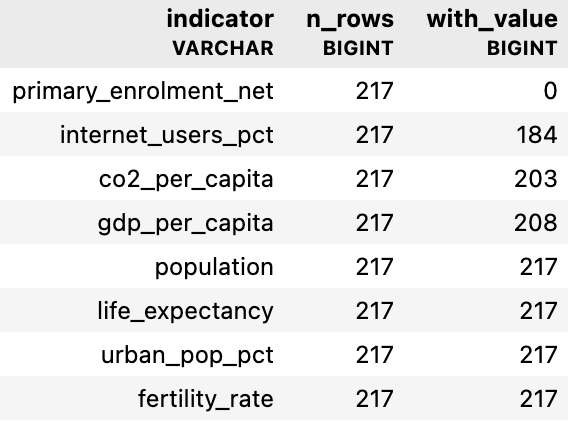

**Query 2 Results:**<br>
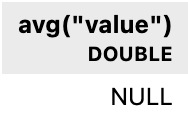<br>
**SQL gave us "NULL" instead of an error because "NULL" means unknown. So, the query was correct, but the mean is just unknown because this indicator has no non-missing values to compute the mean of in 2020.**

**Query 3 Results:**<br>
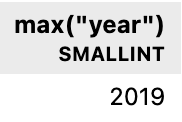<br>
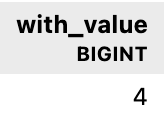

**Before reporting any mean from this panel, we should check the number of rows with missing values.**

### Task 07

Keep the `wdi` view. This question is about how many rich countries there were in each recent year.

Write one query that, for the `gdp_per_capita` indicator:

1. Counts how many countries had a value above 30,000 in each year from 2010 to 2023.
2. Keeps only the years where that count is above 40.
3. Returns the year and the count, ordered by year.

Paste the query and the result table. You should get fewer than fourteen rows: at least one year does not clear the threshold.

Then answer in a few sentences. Two of the conditions you wrote are filters: "value above 30,000" and "count above 40". Say which clause you put each one in, and explain why they cannot be swapped.

Hint: the "WHERE and HAVING" slide of lecture 22 uses `WHERE` on a row condition and `HAVING` on an aggregate in the same query. The "COUNT(\*) and COUNT(value)" slide shows counting inside a `GROUP BY`.

In [ ]:
duckdb.sql("""
    SELECT year,
           COUNT(value) AS n
    FROM wdi
    WHERE indicator = 'gdp_per_capita'
      AND year BETWEEN 2010 AND 2023
      AND value > 30000
    GROUP BY year
    HAVING n > 40
    ORDER BY year
""")

yearSMALLINT,nBIGINT
2010,41
2011,41
2012,41
2013,41
2014,41
2015,43
2016,41
2017,41
2018,41
2019,41


**Result:**<br>
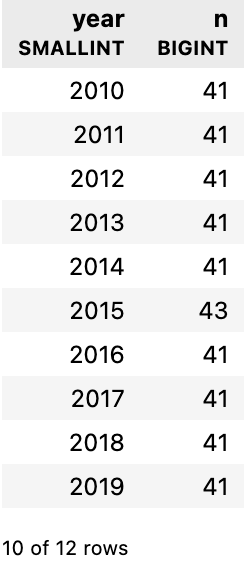<br><br>
**The "value above 30,000" filter is put in the WHERE clause and the "count above 40" filter is put in the HAVING clause. These can't be swapped because WHERE filters rows before grouping and HAVING filters after. The "value above 30,000" is about rows so it goes in WHERE and the "count above 40" is about groups so it goes in HAVING.**

### Task 08

Keep the `wdi` view. The "CASE" slide of lecture 22 put seven countries into income bands. This task does the same for every country and counts them.

Write one query that, for the `gdp_per_capita` indicator in 2020, puts each country into one of these five groups and returns one row per group with the number of countries in it, largest group first:

- `No data`: the value is missing
- `High income`: 13,846 and above
- `Upper middle`: 4,466 and above
- `Lower middle`: 1,136 and above
- `Low income`: everything else

Paste the query and the result. The five counts should add up to 217.

Then answer two things.

1. Delete the `No data` line from your `CASE` and run the query again. Paste the result, and say which group grew, by how many, and why.
2. In one sentence: why is the result of question 1 wrong even though the query ran without an error?

Hint: the "CASE" and "GROUP BY" slides of lecture 22. You can group by the name you give the `CASE` column.

In [35]:
duckdb.sql("""
    SELECT COUNT(*) AS n,
        CASE
            WHEN value IS NULL  THEN 'No data'
            WHEN value >= 13846 THEN 'High income'
            WHEN value >= 4466  THEN 'Upper middle'
            WHEN value >= 1136  THEN 'Lower middle'
            ELSE 'Low income'
        END AS income_band
    FROM wdi
    WHERE indicator = 'gdp_per_capita' AND year = 2020
    GROUP BY income_band
    ORDER BY n DESC
""")

nBIGINT,income_bandVARCHAR
71,High income
57,Lower middle
52,Upper middle
28,Low income
9,No data


**Result:**<br>
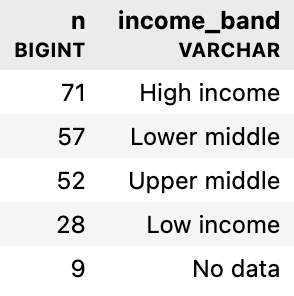

In [37]:
# Question 1
duckdb.sql("""
    SELECT COUNT(*) AS n,
        CASE
            WHEN value >= 13846 THEN 'High income'
            WHEN value >= 4466  THEN 'Upper middle'
            WHEN value >= 1136  THEN 'Lower middle'
            ELSE 'Low income'
        END AS income_band
    FROM wdi
    WHERE indicator = 'gdp_per_capita' AND year = 2020
    GROUP BY income_band
    ORDER BY n DESC
""")

nBIGINT,income_bandVARCHAR
71,High income
57,Lower middle
52,Upper middle
37,Low income


**Result:**<br>
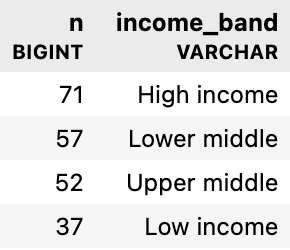

**1. The "Low income" group grew by 9. This is because that was the amount that was previously in the "No data" group and now that this condition is removed, all of those rows fall into the ELSE condition, which is "Low income."**

**2. Even though the query ran without error, these results are wrong because they were NULL values, meaning they were missing, and not necessarily in the "Low income" group.**

### Task 09

Keep the `wdi` view. This task ranks countries by life expectancy in 2000 and in 2020, then looks at five of them.

Write a query that returns four columns for Brazil, China, India, Japan and the United States: the year, the country, the life expectancy rounded to one decimal place, and the country's rank in that year among all 217 countries, highest first. Return the years 2000 and 2020 only, sorted by country and then year. You should get ten rows.

The ranks must be computed among all 217 countries, not among the five. That means ranking first and choosing the five countries afterwards. The "DESCRIBE and SUMMARIZE" slide shows the pattern: a query can select from the result of another query written inside brackets.

Paste the query and the result.

Then answer three things.

1. Move the five-country condition into the `WHERE` clause of the ranking query itself and run it again. Paste the result and say what happened to the ranks, and why.
2. The United States' life expectancy went up between 2000 and 2020, and its rank got worse. Say how both can be true.
3. Pick one other country from your result and say in one sentence what its two ranks tell you.

Hint: the "Window functions" and "Ranking with a window" slides of lecture 22.

In [41]:
duckdb.sql("""
    SELECT country, year, life_exp, rank
    FROM (SELECT country, year, ROUND(value, 1) AS life_exp,
           RANK() OVER (PARTITION BY year ORDER BY value DESC) AS rank
    FROM wdi
    WHERE indicator = 'life_expectancy'
      AND year IN (2000, 2020))
    WHERE country IN ('Brazil', 'China', 'India', 'Japan', 'United States')
    ORDER BY country, year
""")

countryVARCHAR,yearSMALLINT,life_expDOUBLE,rankBIGINT
Brazil,2000,69.6,120
Brazil,2020,74.5,94
China,2000,72.3,87
China,2020,78.0,56
India,2000,62.7,157
India,2020,70.2,142
Japan,2000,81.1,3
Japan,2020,84.6,3
United States,2000,76.6,38
United States,2020,77.0,67


**Result:**<br>
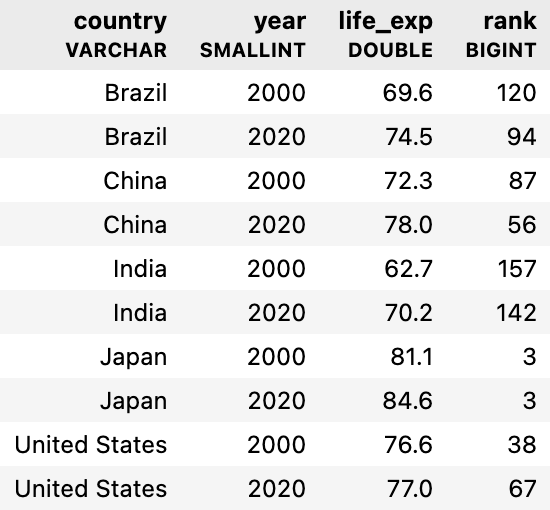

In [ ]:
# moving the 5 country condition into the WHERE clause of the ranking
duckdb.sql("""
    SELECT country, year, life_exp, rank
    FROM (SELECT country, year, ROUND(value, 1) AS life_exp,
           RANK() OVER (PARTITION BY year ORDER BY value DESC) AS rank
    FROM wdi
    WHERE indicator = 'life_expectancy'
        AND country IN ('Brazil', 'China', 'India', 'Japan', 'United States')
        AND year IN (2000, 2020))
    ORDER BY country, year
""")

countryVARCHAR,yearSMALLINT,life_expDOUBLE,rankBIGINT
Brazil,2000,69.6,4
Brazil,2020,74.5,4
China,2000,72.3,3
China,2020,78.0,2
India,2000,62.7,5
India,2020,70.2,5
Japan,2000,81.1,1
Japan,2020,84.6,1
United States,2000,76.6,2
United States,2020,77.0,3


**Result:**<br>
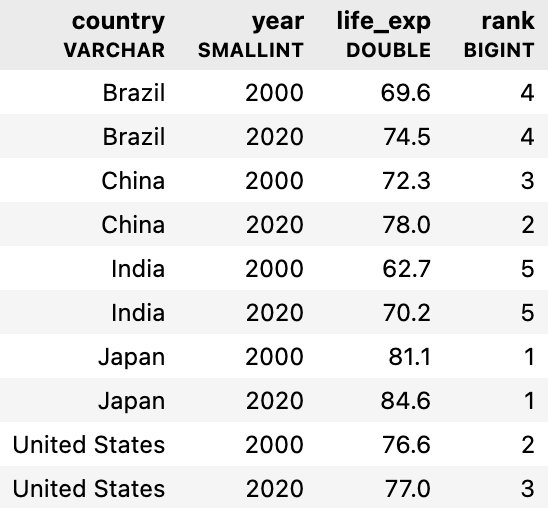

**1. The ranks are now only computed among the 5 countries, not all 217 countries. This is because the 5 country condition was moved inside the inner query's WHERE clause, so this filtering was done prior to the ranking, leaving only the 5 countries to be ranked.**<br><br>
**2. The United States life expectancy increased from 2000 to 2020, but its rank got worse because other countries previously below them in 2000 increased their own life expectancies above the United States in 2020.**<br><br>
**3. In 2000 and 2020, Japan's life expectancy was 81.1 and 84.6 years, respectively, which were the 3rd highest life expectancies among all 217 countries in both years.**

### Task 10

This task joins two small tables. Keep the `wdi` view from task 06, then run these four statements from the "Two small tables" slide of lecture 22.

```python
duckdb.sql("""
    CREATE OR REPLACE TABLE gdp2020 AS
    SELECT country, iso3, ROUND(value, 0) AS gdp_per_capita
    FROM wdi
    WHERE indicator = 'gdp_per_capita' AND year = 2020
      AND iso3 IN ('USA','BRA','CHN','IND','DEU','JPN')
""")
```

```python
duckdb.sql("""
    CREATE OR REPLACE TABLE regions
        (iso3 VARCHAR PRIMARY KEY, region VARCHAR)
""")
```

```python
duckdb.sql("""
    INSERT INTO regions VALUES
        ('USA', 'North America'), ('BRA', 'Latin America'),
        ('CHN', 'East Asia'),     ('IND', 'South Asia'),
        ('DEU', 'Europe'),        ('KOR', 'East Asia'),
        ('AUS', 'Oceania')
""")
```

```python
duckdb.sql("SELECT * FROM regions ORDER BY iso3")
```

There are six rows in `gdp2020` and seven in `regions`. `JPN` has a GDP figure and no region. `KOR` and `AUS` have a region and no GDP figure.

Write one query that lists every country with a 2020 GDP figure, with three columns: the country, its GDP per capita, and its region. Every country in `gdp2020` must appear, Japan included. Where the region is missing, show `No region` instead of an empty cell. Sort by GDP per capita, highest first.

Paste the query and the result. You should get six rows.

Then answer in a few sentences. Which table has to be the one named in `FROM` this time, and why? Korea and Australia are in `regions` but not in your result: why not? What did `COALESCE` change?

Hint: the "LEFT JOIN" and "Missing values" slides of lecture 22. Appendix 01 answers a different question: there, every region had to survive.

In [43]:
duckdb.sql("""
    CREATE OR REPLACE TABLE gdp2020 AS
    SELECT country, iso3, ROUND(value, 0) AS gdp_per_capita
    FROM wdi
    WHERE indicator = 'gdp_per_capita' AND year = 2020
      AND iso3 IN ('USA','BRA','CHN','IND','DEU','JPN')
""")

CountBIGINT
6


In [44]:
duckdb.sql("""
    CREATE OR REPLACE TABLE regions
        (iso3 VARCHAR PRIMARY KEY, region VARCHAR)
""")

CountBIGINT


In [45]:
duckdb.sql("""
    INSERT INTO regions VALUES
        ('USA', 'North America'), ('BRA', 'Latin America'),
        ('CHN', 'East Asia'),     ('IND', 'South Asia'),
        ('DEU', 'Europe'),        ('KOR', 'East Asia'),
        ('AUS', 'Oceania')
""")

CountBIGINT
7


In [46]:
duckdb.sql("SELECT * FROM regions ORDER BY iso3")

iso3VARCHAR,regionVARCHAR
AUS,Oceania
BRA,Latin America
CHN,East Asia
DEU,Europe
IND,South Asia
KOR,East Asia
USA,North America


In [47]:
duckdb.sql("""
    SELECT g.country, g.gdp_per_capita, COALESCE(r.region, 'No region') AS region
    FROM gdp2020 AS g
    LEFT JOIN regions AS r ON g.iso3 = r.iso3
    ORDER BY g.gdp_per_capita DESC
""")

countryVARCHAR,gdp_per_capitaDOUBLE,regionVARCHAR
United States,59534.0,North America
Germany,42373.0,Europe
Japan,35363.0,No region
China,10573.0,East Asia
Brazil,8435.0,Latin America
India,1807.0,South Asia


**Result:**<br>
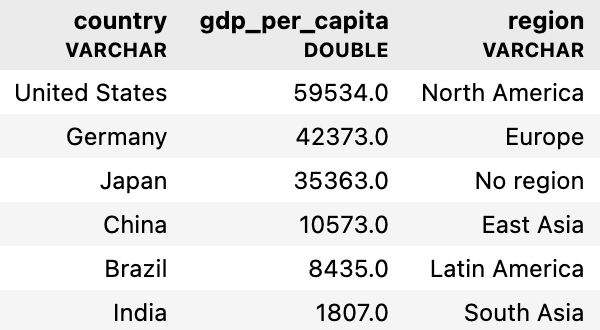<br><br>

**gdp2020 has to be the one named in FROM because this table has a row for each country we want, which will all be kept in the join. Korea and Australia are in regions but not in the result because they don't have a matching country code in gdp2020 that would have those values in the region column. COALESCE replaced the NULL value for Japan's region with "No region" in the query result.**

### Resources Used
- I used the following lecture notes to complete the assignment: "Lecture 21 - Parallel Computing Fundamentals" (https://danilofreire.github.io/datasci350/lectures/lecture-21/21-parallel-computing.html) and "Lecture 22 - SQL Revision with DuckDB" (https://danilofreire.github.io/datasci350/lectures/lecture-22/22-sql-revision.html)
- I did not use any AI tools to complete this assignment